### Name: Mithun Kumar Rajak
### JLU ID: JLU08355
### Roll NO. : 2023BTCSE010
### Course: Soft Computing (EL1)
### Course Code: STDA2102


### Question 1:

To understand and implement the basic working of an artificial neuron using Python.

In [1]:
import numpy as np

# Step activation function
def step_activation(z):
    return 1 if z >= 0 else 0

print("[Q1] Step activation ready")

[Q1] Step activation ready


In [2]:
# Artificial neuron model: z = x·w + b
def artificial_neuron(inputs, weights, bias, activation=step_activation):
    weighted_sum = np.dot(inputs, weights)
    z = weighted_sum + bias
    output = activation(z)
    return weighted_sum, z, output

print("[Q1] Artificial neuron defined")

[Q1] Artificial neuron defined


In [3]:
# Single neuron forward pass
inputs = np.array([0.5, 0.8])
weights = np.array([0.4, 0.7])
bias = -0.5

weighted_sum, z, output = artificial_neuron(inputs, weights, bias)

# Display input, weighted sum, and output
print(f"[Q1] Inputs: {inputs}, z: {z:.2f}, Output: {output}")

[Q1] Inputs: [0.5 0.8], z: 0.26, Output: 1


In [4]:
# Test neuron on multiple input vectors
test_cases = [
    np.array([0.1, 0.2, 0.3]),
    np.array([0.9, 0.9, 0.9]),
    np.array([-0.5, 0.4, 0.1]),
]
test_weights = np.array([0.4, 0.7, 0.5])

# Print output for each test case
for i, x in enumerate(test_cases, start=1):
    ws, z, out = artificial_neuron(x, test_weights, bias)
    print(f"[Q1] Case {i}: x={x}, z={round(z,4)}, out={out}")

[Q1] Case 1: x=[0.1 0.2 0.3], z=-0.17, out=0
[Q1] Case 2: x=[0.9 0.9 0.9], z=0.94, out=1
[Q1] Case 3: x=[-0.5  0.4  0.1], z=-0.37, out=0


---

### Question 2:

To implement the weighted sum of inputs and bias used in an artificial neuron using Python.

In [5]:
import numpy as np

# Linear combination: z = (x · w) + b
def calculate_weighted_sum(inputs, weights, bias):
    return np.dot(inputs, weights) + bias

print("[Q2] Weighted sum function ready")

[Q2] Weighted sum function ready


In [6]:
# Verify manual arithmetic against vector dot product
x = np.array([1.0, 2.0, 3.0])
w = np.array([0.2, 0.5, -0.1])
b = 1.0

manual_z = (x[0]*w[0] + x[1]*w[1] + x[2]*w[2]) + b
z = calculate_weighted_sum(x, w, b)

# Compare both results
print(f"[Q2] Manual: {manual_z:.4f} | Vector: {z:.4f} | Matched: {manual_z == z}")

[Q2] Manual: 1.9000 | Vector: 1.9000 | Matched: True


In [7]:
# Compute weighted sum for a batch of samples
X = np.array([
    [1.0, 0.5, -1.0],
    [0.2, 0.8, 0.3],
    [-0.4, -0.6, 0.9],
])
w = np.array([0.5, -0.2, 0.7])
b = 0.1

# Print result for each sample row
for i, row in enumerate(X, start=1):
    z = calculate_weighted_sum(row, w, b)
    print(f"[Q2] Sample {i}: z={round(z, 4)}")

[Q2] Sample 1: z=-0.2
[Q2] Sample 2: z=0.25
[Q2] Sample 3: z=0.65


---

### Question 3:

To implement and visualize Sigmoid, Tanh, and ReLU activation functions using Python.

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Sigmoid, Tanh, ReLU activations and derivatives
def sigmoid(x): return 1 / (1 + np.exp(-x))
def tanh(x): return np.tanh(x)
def relu(x): return np.maximum(0, x)

def sigmoid_der(x): s = sigmoid(x); return s * (1 - s)
def tanh_der(x): return 1 - np.tanh(x)**2
def relu_der(x): return np.where(x > 0, 1, 0)

print("[Q3] Activations & derivatives ready")

[Q3] Activations & derivatives ready


In [9]:
# Evaluate activation functions at sample points
x_samples = [-2, 0, 2]

# Print computed values
for val in x_samples:
    print(f"[Q3] x={val:>2} -> sig: {sigmoid(val):.3f}, tanh: {tanh(val):.3f}, relu: {relu(val):.3f}")

[Q3] x=-2 -> sig: 0.119, tanh: -0.964, relu: 0.000
[Q3] x= 0 -> sig: 0.500, tanh: 0.000, relu: 0.000
[Q3] x= 2 -> sig: 0.881, tanh: 0.964, relu: 2.000


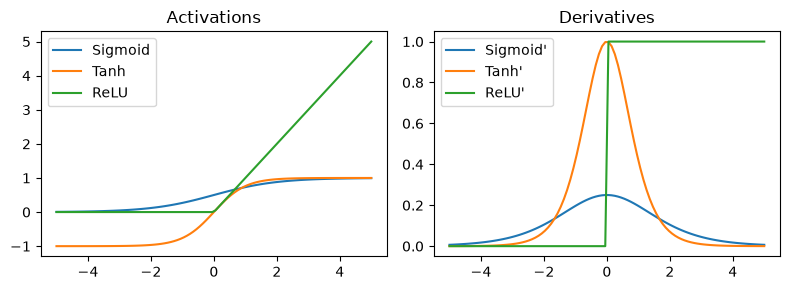

[Q3] Plots generated successfully


In [10]:
# Plot activation curves and derivatives over [-5, 5]
x = np.linspace(-5, 5, 100)
plt.figure(figsize=(8, 3))

plt.subplot(1, 2, 1)
plt.plot(x, sigmoid(x), label='Sigmoid')
plt.plot(x, tanh(x), label='Tanh')
plt.plot(x, relu(x), label='ReLU')
plt.title('Activations'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(x, sigmoid_der(x), label="Sigmoid'")
plt.plot(x, tanh_der(x), label="Tanh'")
plt.plot(x, relu_der(x), label="ReLU'")
plt.title('Derivatives'); plt.legend()

plt.tight_layout()
plt.show()

print("[Q3] Plots generated successfully")

---

### Question 4:

To create a simple single-layer neural network using Python.

In [11]:
import numpy as np

# Perceptron model with learning rule: w += lr * error * x
class Perceptron:
    def __init__(self, n_inputs, lr=0.1):
        self.w = np.zeros(n_inputs)
        self.b = 0.0
        self.lr = lr

    def predict(self, x):
        return 1 if (np.dot(x, self.w) + self.b) >= 0 else 0

    def train(self, X, y, epochs=10):
        for _ in range(epochs):
            for xi, target in zip(X, y):
                error = target - self.predict(xi)
                self.w += self.lr * error * xi
                self.b += self.lr * error

print("[Q4] Perceptron class ready")

[Q4] Perceptron class ready


In [12]:
# Train Perceptron on AND gate
X = np.array([[0,0], [0,1], [1,0], [1,1]])
y = np.array([0, 0, 0, 1])

p = Perceptron(n_inputs=2, lr=0.1)
p.train(X, y, epochs=10)

# Display learned weights and bias
print(f"[Q4] Trained -> w: {p.w}, b: {p.b:.2f}")

[Q4] Trained -> w: [0.2 0.1], b: -0.20


In [13]:
# Test Perceptron predictions against truth table
for xi, target in zip(X, y):
    pred = p.predict(xi)
    print(f"[Q4] in: {xi}, target: {target}, pred: {pred}")

print("[Q4] AND gate learned successfully")

[Q4] in: [0 0], target: 0, pred: 0
[Q4] in: [0 1], target: 0, pred: 0
[Q4] in: [1 0], target: 0, pred: 0
[Q4] in: [1 1], target: 1, pred: 1
[Q4] AND gate learned successfully


---

### Question 5:

To create a Multilayer Perceptron (MLP) with input, hidden, and output layers using Keras/TensorFlow.

In [14]:
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

# XOR dataset setup (non-linearly separable)
X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype='float32')
y = np.array([0, 1, 1, 0], dtype='float32')

print("[Q5] XOR dataset ready")

[Q5] XOR dataset ready


In [ ]:
# Build and train MLP (hidden layer with ReLU, output with Sigmoid)
model = keras.Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(4, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy')
model.fit(X, y, epochs=500, verbose=0)

# Predict and display XOR results
preds = (model.predict(X, verbose=0) > 0.5).astype(int).flatten()
print(f"[Q5] Targets: {y.astype(int).tolist()}")
print(f"[Q5] Preds  : {preds.tolist()}")
print("[Q5] XOR solved successfully")

---

### Question 6:

To apply Gradient Descent for updating the weights of a simple neural network during training.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Sigmoid activation and binary cross-entropy loss
def sigmoid(z): return 1 / (1 + np.exp(-z))
def compute_loss(y_true, y_pred):
    return -np.mean(y_true * np.log(y_pred + 1e-9) + (1-y_true) * np.log(1-y_pred + 1e-9))

print("[Q6] Functions ready")

In [ ]:
# Train single neuron using Gradient Descent
X_q6 = np.array([0.1, 0.3, 0.6, 0.8, 1.2, 1.5, 1.8, 2.0])
y_q6 = np.array([0, 0, 0, 0, 1, 1, 1, 1], dtype=float)
w, b, lr = 0.0, 0.0, 0.5
losses = []

for epoch in range(100):
    z = w * X_q6 + b
    y_p = sigmoid(z)
    losses.append(compute_loss(y_q6, y_p))
    dz = y_p - y_q6
    w -= lr * np.mean(dz * X_q6)
    b -= lr * np.mean(dz)

# Print loss reduction and learned parameters
print(f"[Q6] Loss: {losses[0]:.4f} -> {losses[-1]:.4f}")
print(f"[Q6] w: {w:.4f}, b: {b:.4f}")

# Plot loss convergence curve
plt.figure(figsize=(5, 2.5))
plt.plot(losses)
plt.title("Loss Curve")
plt.show()
print("[Q6] Loss minimized successfully")

---

### Question 7:

To understand and implement the basic concept of Backpropagation for training a neural network.

In [ ]:
import numpy as np

# Sigmoid activation and derivative for backpropagation
def sig(z): return 1 / (1 + np.exp(-z))
def sig_d(a): return a * (1 - a)

print("[Q7] Functions ready")

In [ ]:
# Forward and backward pass with error propagation
def backprop_step(X, y, w1, w2, lr=0.1):
    # Forward pass through hidden and output layers
    z1 = np.dot(X, w1)
    a1 = sig(z1)
    z2 = np.dot(a1, w2)
    a2 = sig(z2)

    # Backward pass using chain rule
    d2 = (a2 - y) * sig_d(a2)
    d1 = np.dot(d2, w2.T) * sig_d(a1)

    # Weight updates
    w2 -= lr * np.dot(a1.T, d2)
    w1 -= lr * np.dot(X.T, d1)

    return np.mean((a2 - y)**2)

print("[Q7] Backprop step ready")

In [ ]:
# Train 2-layer network on XOR using backpropagation
X_xor = np.array([[0,0], [0,1], [1,0], [1,1]])
y_xor = np.array([[0], [1], [1], [0]])
np.random.seed(1)
w1, w2 = np.random.randn(2,2), np.random.randn(2,1)

for i in range(5000):
    err = backprop_step(X_xor, y_xor, w1, w2)

# Display final MSE and XOR predictions
preds = (sig(np.dot(sig(np.dot(X_xor, w1)), w2)) > 0.5).astype(int).flatten()
print(f"[Q7] Final MSE: {err:.6f}")
print(f"[Q7] XOR preds: {preds}")
print("[Q7] Backprop trained successfully")

---

### Question 8:

To train a simple neural network model on a dataset using Keras/TensorFlow.

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras

# Load dataset, split train/test, and scale features
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.2, random_state=42)
sc = StandardScaler()
X_train, X_test = sc.fit_transform(X_train), sc.transform(X_test)

print(f"[Q8] Train: {X_train.shape[0]}, Test: {X_test.shape[0]} samples")

In [ ]:
# Build and train binary classifier using Keras
model_bc = keras.Sequential([
    keras.layers.Input(shape=(30,)),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])
model_bc.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_bc.fit(X_train, y_train, epochs=20, verbose=0)

# Evaluate training loss and accuracy
loss, acc = model_bc.evaluate(X_train, y_train, verbose=0)
print(f"[Q8] Train loss: {loss:.4f}, acc: {acc*100:.2f}%")
print("[Q8] Model trained successfully")

---

### Question 9:

To evaluate the performance of a trained neural network using suitable evaluation metrics in Python.

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

# Evaluate model predictions on test set
y_pred = (model_bc.predict(X_test, verbose=0) > 0.5).astype(int)
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"[Q9] Test acc: {acc*100:.2f}%")
print(f"[Q9] Confusion matrix:\n{cm}")

In [ ]:
from sklearn.metrics import roc_auc_score, classification_report

# Compute ROC-AUC score and classification report
roc_auc = roc_auc_score(y_test, model_bc.predict(X_test, verbose=0))

print(f"[Q9] ROC-AUC: {roc_auc:.4f}")
print(f"[Q9] Report:\n{classification_report(y_test, y_pred, digits=3)}")
print("[Q9] Evaluation complete")

---

### Question 10:

To design, train, and evaluate a complete Artificial Neural Network-based classification system using Python and Keras/TensorFlow by integrating input features, hidden layers, activation functions, training, and model evaluation.

In [ ]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from tensorflow import keras

# Load and standardize Wine dataset (13 features, 3 classes)
wine = load_wine()
X, y = wine.data, keras.utils.to_categorical(wine.target, 3)
X = StandardScaler().fit_transform(X)

# Build and train multi-class ANN classifier
model_wine = keras.Sequential([
    keras.layers.Input(shape=(13,)),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(3, activation='softmax')
])
model_wine.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_wine.fit(X, y, epochs=50, verbose=0)

# Evaluate overall system performance
loss, acc = model_wine.evaluate(X, y, verbose=0)
print(f"[Q10] Loss: {loss:.4f}, Acc: {acc*100:.2f}%")
print("[Q10] System completed successfully")

---